# MoMa 02 - Simulation study: catching low-abundance genes (TYR, MAOA/B, ALDH1A1) in DA and LC neurons

**Project:** MoMa (ASAP-030013) - **Code:** `sim/lowgene_sim.py` (pure numpy/scipy; synthetic data only, runs anywhere)

Everything in this notebook is **synthetic**. The simulation is calibrated to structural facts of the Lee SN
dataset seen in notebook 01 (counts of nuclei and sequencing depth, no expression values) and to published
external anchors:

| fact | value | consequence |
|---|---|---|
| marker-defined DA nuclei, Lee SN | **217** in total, 25 donors (median ~5/donor, max 30) | the bottleneck is the *number* of DA neurons, not depth |
| UMIs per DA nucleus, Lee | ~11,000 (per-donor median 12,000) | per-nucleus detection of MAOA/ALDH1A1 is fine; TYR stays sparse |
| curated `final` object | 3,000 HVGs; **none** of the panel genes | expression must come from the all-gene matrix |
| pipeline labels of the 217 DA nuclei | 159 "Unknown", 27 GABAergic, 22 oligodendrocyte | DA neurons must be re-called from markers |
| "unfiltered" object | 1.3 M barcodes, median 59 UMIs, 77% below 500 | "raw" must NOT mean "all barcodes" |
| Kamath et al. 2022 DA nuclei (FANS-enriched, ~22k, ~8,000 UMIs each) | TYR has >= 1 UMI in only ~1-5% of SOX6/AGTR1 DA nuclei (Chatterton/Halliday re-analysis) | TYR abundance ~1e-6 to 6e-6 of UMIs: the **"plausible" scenario is the realistic one**, "optimistic" is a ceiling |
| Edwards/Chatterton TH-mask GeoMx (public object, 348 ROIs) | MAOA ~10, MAOB ~9, ALDH1A1 ~12, TH ~22 counts per ~120-cell ROI (library ~1.2e5); TYR below the limit of quantification | GeoMx WTA resolves the moderate genes per stage; TYR needs targeted probes or in situ detection |

Gene abundance priors (fraction of a neuron's UMIs; replace with measured values from notebook 01):
TH 5e-3, ALDH1A1 1e-3, MAOA 3e-4, MAOB 1e-4 (in neurons; ~15x higher in astrocytes),
TYR 1e-5 (optimistic ceiling) / 2e-6 (plausible, matches the Kamath detection rate) / 5e-7 (pessimistic).


In [1]:
import subprocess, sys, pandas as pd
from pathlib import Path
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "sim").exists() else Path.cwd().parent
SIM = ROOT / "sim"
FAST = False            # True = fewer replicates (~30 s); False = full run (~4 min)
cmd = [sys.executable, str(SIM / "lowgene_sim.py")] + (["--fast"] if FAST else [])
print(subprocess.run(cmd, capture_output=True, text=True, cwd=ROOT).stdout[-1500:])
res = pd.read_csv(SIM / "sim_results.csv")
show = lambda name: display(Image(filename=str(SIM / "figures" / name)))

S1 detection vs depth
  wrote figures/S1_detection_vs_depth.png
  (1s)
S2 HVG selection
  wrote figures/S2_hvg_selection_drops_panel.png
  (9s)
S3 QC and ambient trap
  wrote figures/S3_qc_ambient_trap.png
  (3s)
S4 donor-level power PD vs control
  wrote figures/S4_power_pd_vs_control.png
  (37s)
S5 subtype contrast
  wrote figures/S5_subtype_power_vs_pooled_nuclei.png
  (22s)
S6 binarisation and pseudoreplication traps
  wrote figures/S6_noise_amplification_traps.png
  (15s)
S7 GeoMx designs
  wrote figures/S7_geomx_designs.png
  (310s)
S8 bulk composition confound
  wrote figures/S8_bulk_composition_confound.png
  (5s)
wrote sim_results.csv (246 rows) in 401s



## S1 - Per-nucleus detection vs. detection in a pooled population

Left: the probability that a single nucleus shows >= 1 UMI is set by depth x abundance. At the ~10,000 UMIs a
DA/NE nucleus carries, MAOA and ALDH1A1 are detected in most nuclei, MAOB in about half, TYR in 10% at best.
Whole-cell scRNA-seq (green) helps by a constant factor only, and there is no whole-cell human post-mortem data.

Right: *whether TYR is expressed at all* in DA or NE neurons is a question about pooled UMIs versus a noise floor
(ambient + mis-mapping, assumed 1e-7 per UMI, to be estimated from the ~1 M cortical nuclei in the cohort where
TYR should be absent, and from SN/pons glia). With Lee's 217 DA nuclei this is answerable only in the optimistic
scenario; the **public human LC pool (~765 NE nuclei: Weber 2024 + Siletti 2023 + Basak 2026)** answers it at the
plausible level; with ~20,000 FANS-enriched DA nuclei (Kamath et al. 2022) it is answerable in all three.


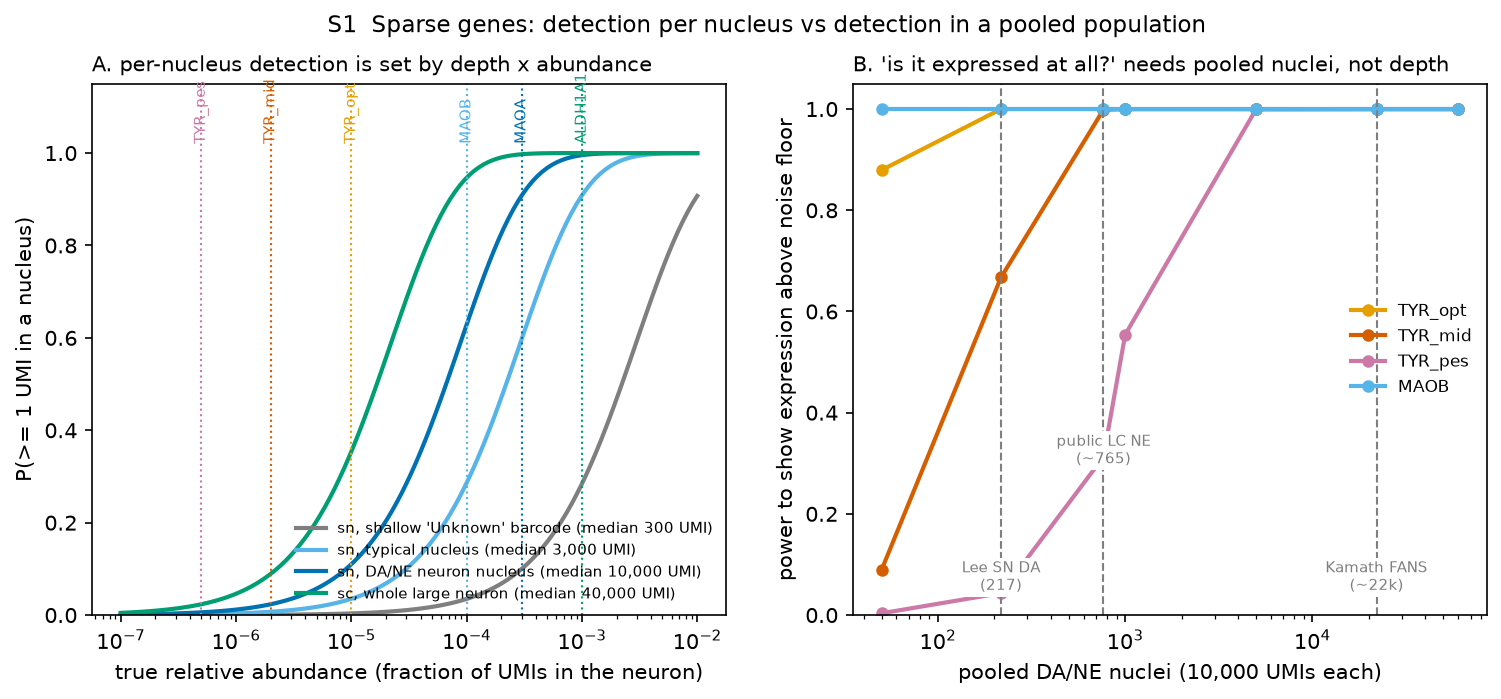

In [2]:
show("S1_detection_vs_depth.png")

## S2 - Why the curated object cannot contain these genes

The pipeline selects 3,000 highly variable genes per batch (Pearson residuals) and keeps the genes selected in the
most batches. Survival depends on *cohort-wide variance*, not on a gene's level in the neurons of interest:
sparse genes (TYR) never make it, and markers of a rare cell type that exists in only some samples (TH: SN samples
only, 1% of nuclei) lose to genes that are variable everywhere. In the real Lee object none of the 15 panel genes
survived; in this synthetic cohort MAOB survives through its astrocyte expression, which only illustrates that
the outcome is a property of the whole cohort. Conclusion: take the QC-passed nuclei and labels from the
curated object, and the counts from the all-gene matrix (`*.merged_cleaned_unfiltered.h5ad`).

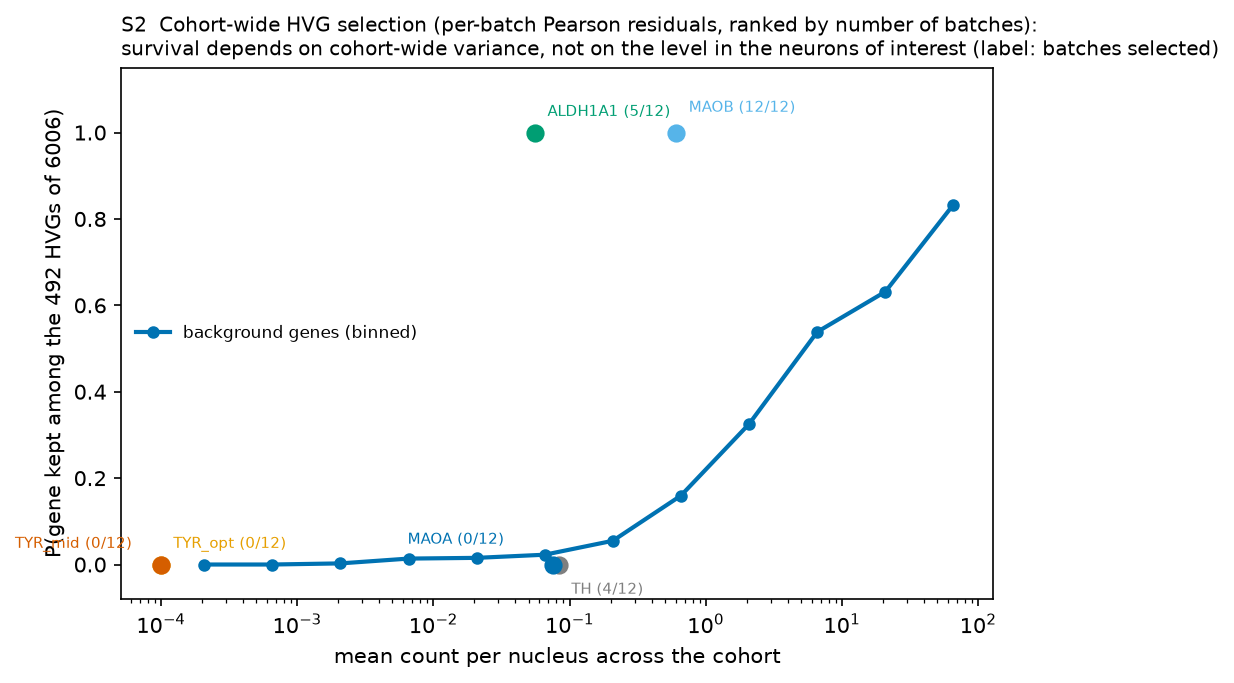

In [3]:
show("S2_hvg_selection_drops_panel.png")

## S3 - The QC / ambient trap, and what "raw" should mean

- **A.** With 1-UMI marker thresholds, ambient TH/DAT produces false DA calls (precision ~0.5-0.6) in both the
  unfiltered and the QC-passed set; real DA nuclei carry ~50 TH UMIs, so a threshold of TH >= 3 and DAT/VMAT2 >= 2
  (or a depth-scaled score) gives precision ~1 at no loss of recall. (Doublets are not simulated; filter them.)
- **B.** MAOB is detected in ~55-60% of DA nuclei, but ~20-25% is expected from ambient astrocytic RNA alone.
- **C.** Pseudobulk CPM in DA nuclei overestimates MAOB by ~40%; subtracting the expected ambient contribution
  (ambient fraction x ambient profile x depth, as estimated from empty droplets / CellBender) recovers the truth.

Using all 1.3 M barcodes adds nothing but false calls and dilution. "Raw" must mean **all genes for QC-passed
nuclei**, with ambient modelled explicitly, and CellRanger vs CellBender counts compared for the panel.

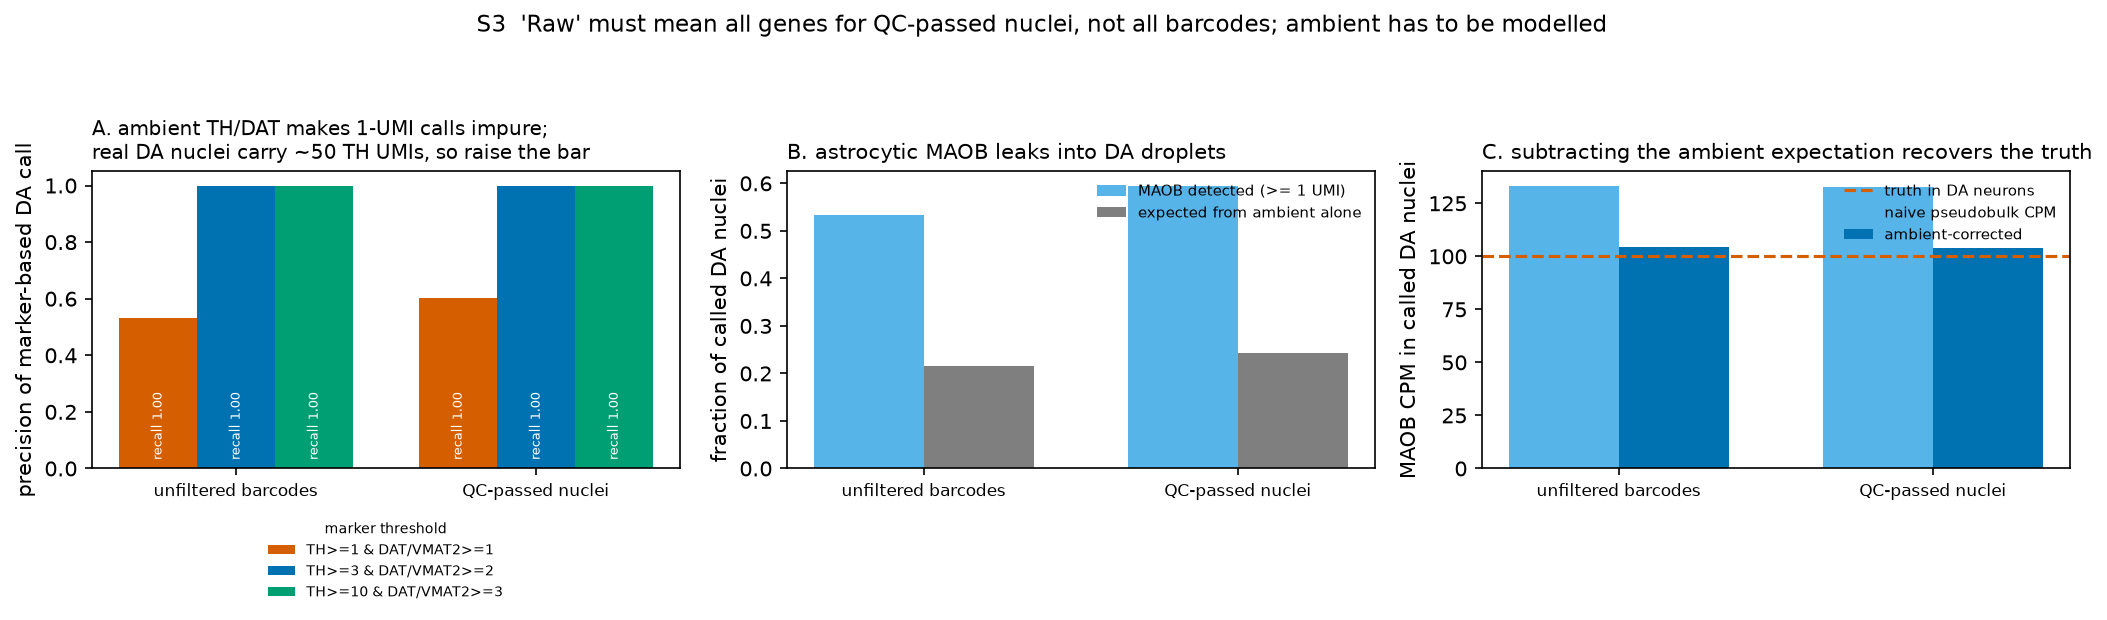

In [4]:
show("S3_qc_ambient_trap.png")

## S4 - Donor-level power, PD vs control (survivor comparison)

Unit = donor; quasi-Poisson GLM on pseudobulk counts with log(total UMIs) offset; 30% donor-level biological CV.
A fold change of 0.5 in surviving PD neurons is the "TYR marks the neurons that die" hypothesis; 0.7 is a subtle effect.

- Lee alone: ALDH1A1 / MAOA / MAOB are testable at FC 0.5 (power 0.87-0.97); TYR is not (<= 0.2).
- Pooling the CRN SN datasets (Lee + Sulzer + Voet) helps the moderate genes, not TYR.
- A FANS-enriched cohort (Kamath-like, ~1,200 DA/donor) or a mega-pool with public data makes TYR testable
  down to the plausible scenario.
- LC: an unsorted pontine dissection (~40 NE neurons/donor) behaves like "CRN pooled"; ~400 enriched NE neurons
  per donor (FANS on PHOX2B/DBH nuclei, or LCM of pigmented neurons) from 10 + 10 donors is the design that works.

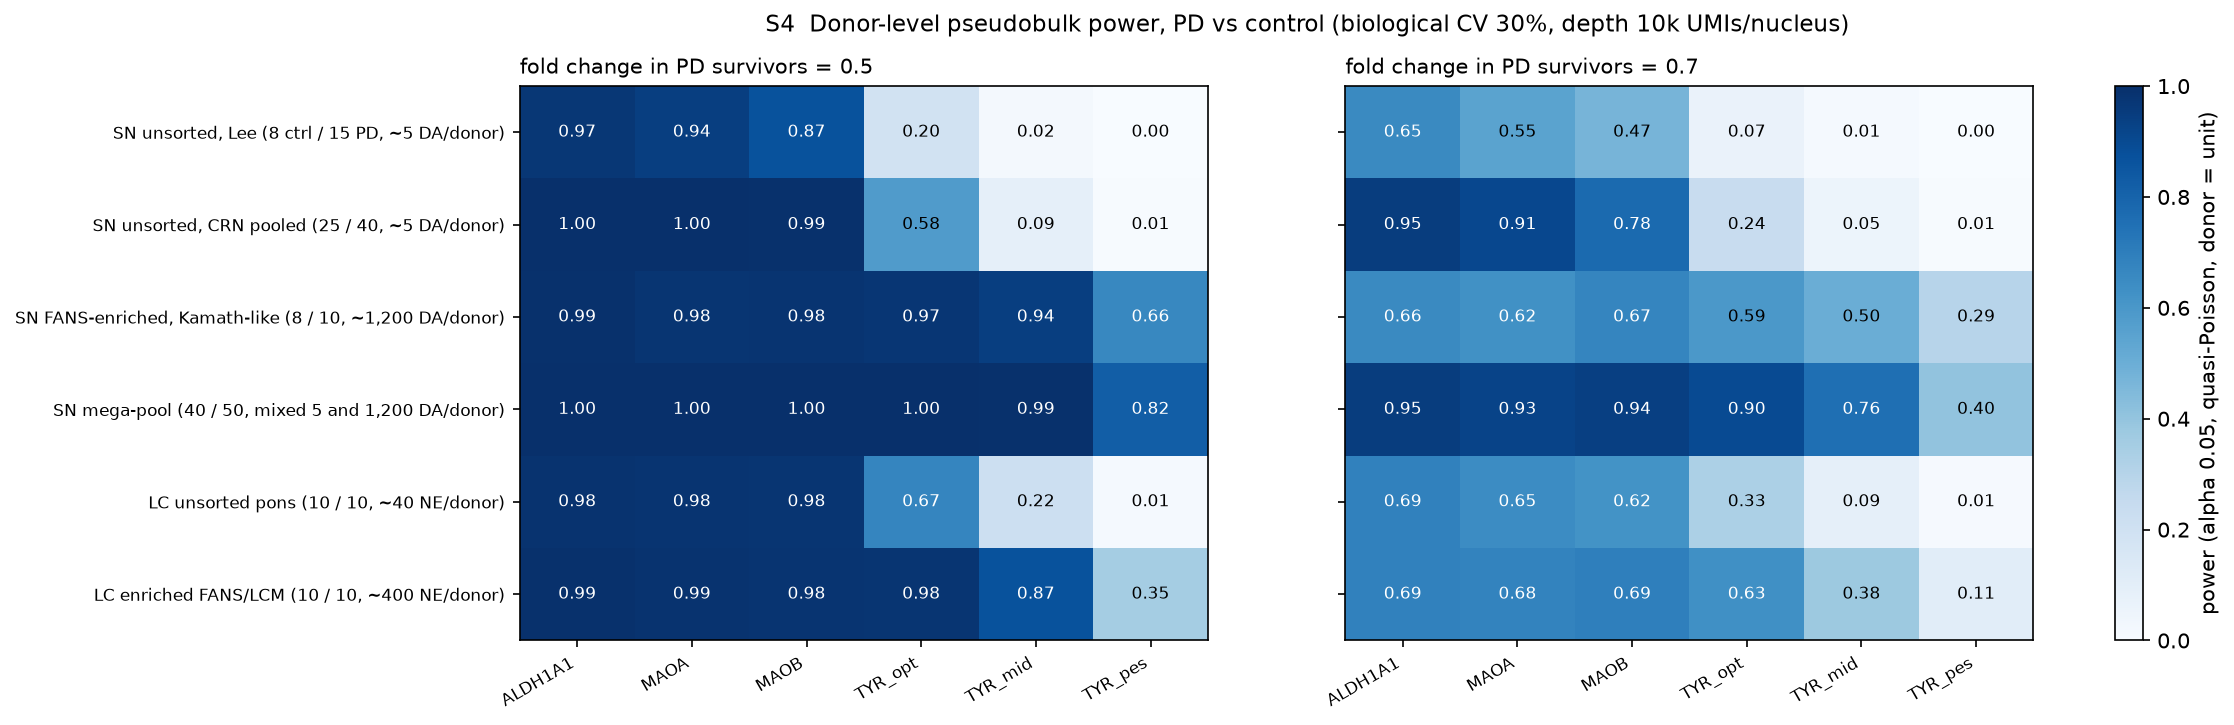

In [5]:
show("S4_power_pd_vs_control.png")

## S5 - Vulnerable vs resistant DA subtype within control brains

The cleanest test of "TYR is higher in the neurons that die" avoids survivor bias altogether: compare
vulnerable (SOX6+/AGTR1+, ventral tier) with resistant (CALB1+, dorsal tier) DA neurons in control donors,
donor-blocked. Power vs the number of pooled control DA nuclei: ~1,000 for the optimistic TYR level,
~5,000-10,000 for the plausible level, ~20,000 for the pessimistic one. Lee has 50 control DA nuclei.

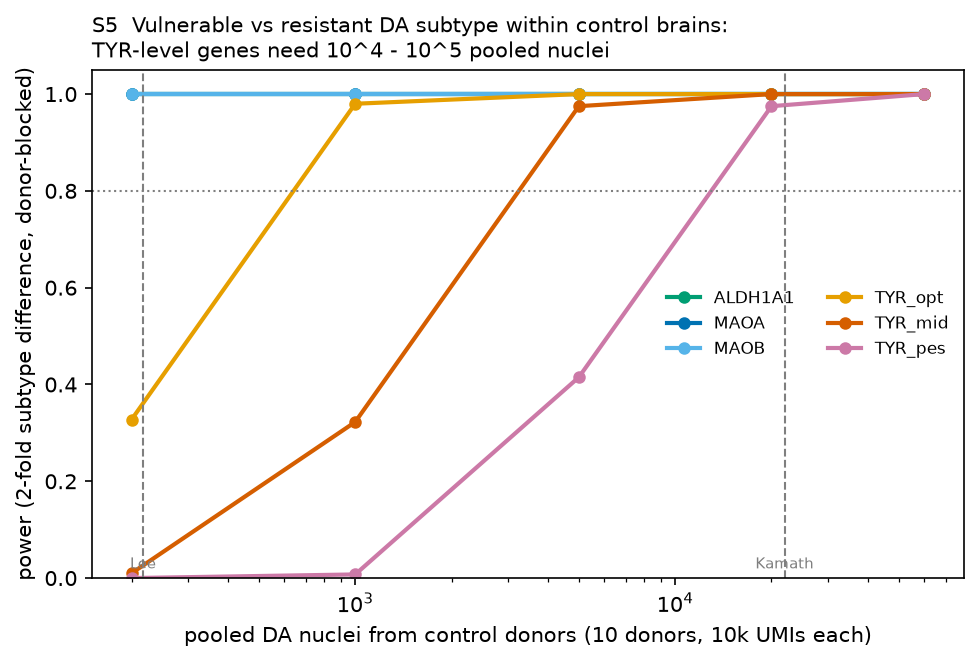

In [6]:
show("S5_subtype_power_vs_pooled_nuclei.png")

## S6 - How count-level analyses amplify noise

- **A.** Splitting nuclei into TYR+ / TYR- by "any UMI" selects deeper nuclei as TYR+. Any second gene that is
  itself sparse then looks "co-expressed" with TYR: Wilcoxon on log-normalised values and detection-rate tests give
  false-positive rates near 100% for MAOB- and MAOA-level genes. A Poisson/NB GLM with a log(depth) offset, or
  depth-matched comparisons, hold the nominal 5%. **Never** correlate two sparse genes across cells without
  modelling depth, and never impute (MAGIC-type smoothing manufactures exactly this correlation).
- **B.** Treating nuclei as replicates with donor-level variation present gives ~80% false positives; the donor
  is the unit of replication.

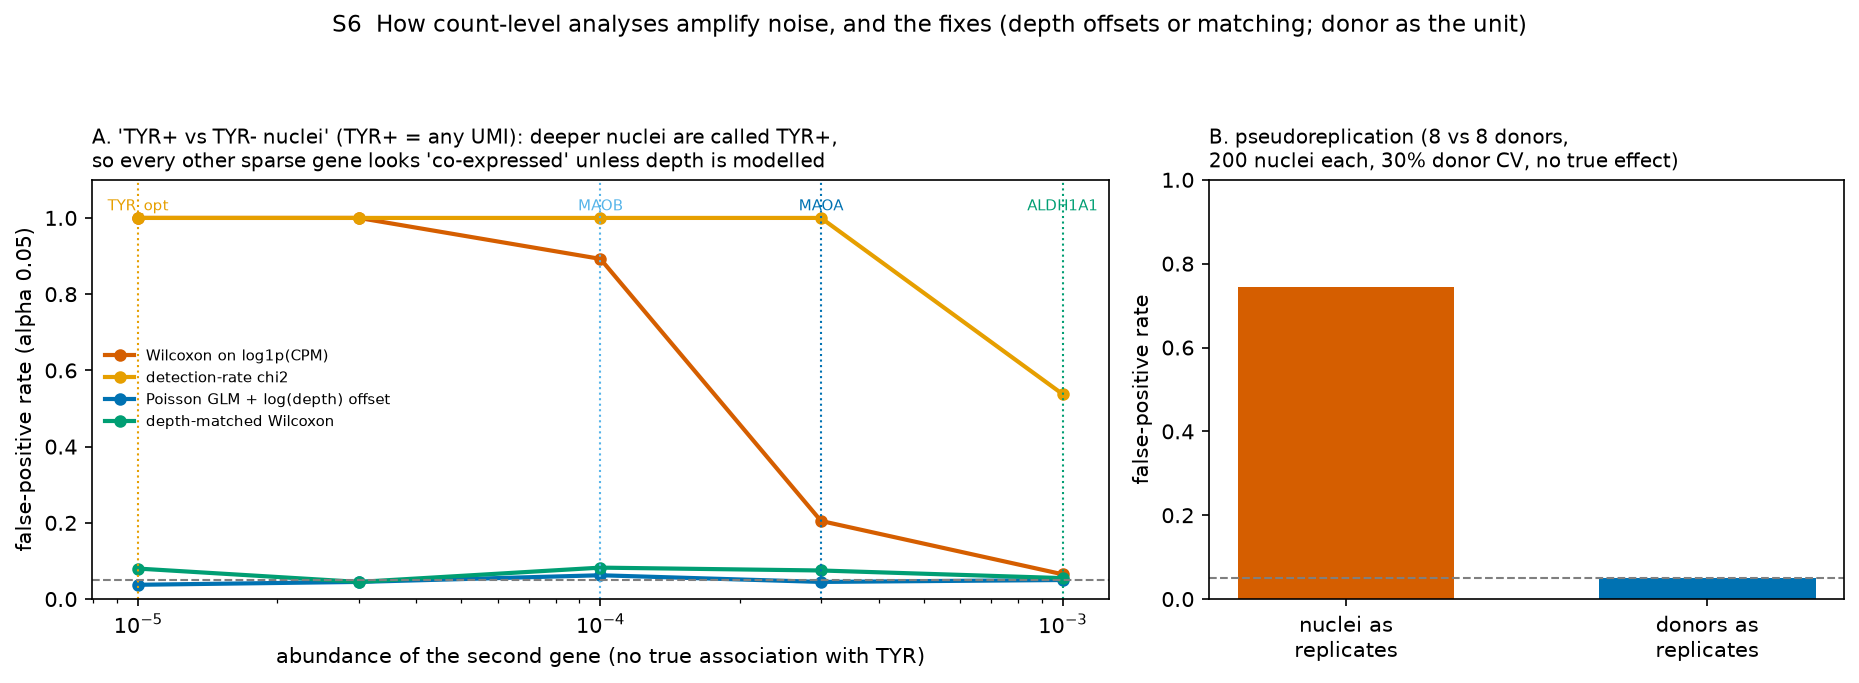

In [7]:
show("S6_noise_amplification_traps.png")

## S7 - TH-masked GeoMx ROIs: deep pseudobulk of the right neurons, with disease stage

A TH+ segment of ~100 cells on the whole-transcriptome panel gives ~1e5 counts per ROI, and the Edwards/Chatterton
(Halliday lab) midbrain dataset in CRN has 348 such ROIs across control / incidental Lewy body disease / early PD /
late PD (10/10/5/5 donors). The simulation is calibrated to the public object: MAOA ~10, MAOB ~9, ALDH1A1 ~12 counts
per ROI, i.e. the moderate genes sit only a few-fold above the negative-probe background, and TYR did not pass the
limit of quantification at all (expected < 1 count per ROI in every scenario). Background must be modelled
additively (it does not scale with the number of cells in the segment; subtracting it naively creates spurious
stage effects when late-stage ROIs contain fewer TH+ cells). Donor is the unit.

**LC.** The Halliday group already ran the same TH-mask workflow on LC (19 donors: 9 control / 8 early PD / 2 late PD,
39 ROIs; embargoed until Dec 2026). The simulation includes that design as it exists (no ILBD stage, so the
ILBD-vs-control column is 0 by construction): it resolves only large (>= 40%/stage) effects for the moderate genes.
The proposed design (8 donors per stage incl. ILBD, ~8 ROIs each) is what a joint LC study would need; a 5/5/5/5
pilot is the minimum worth running. TYR is out of reach for any WTA design; it needs probes (RNAscope / Xenium).


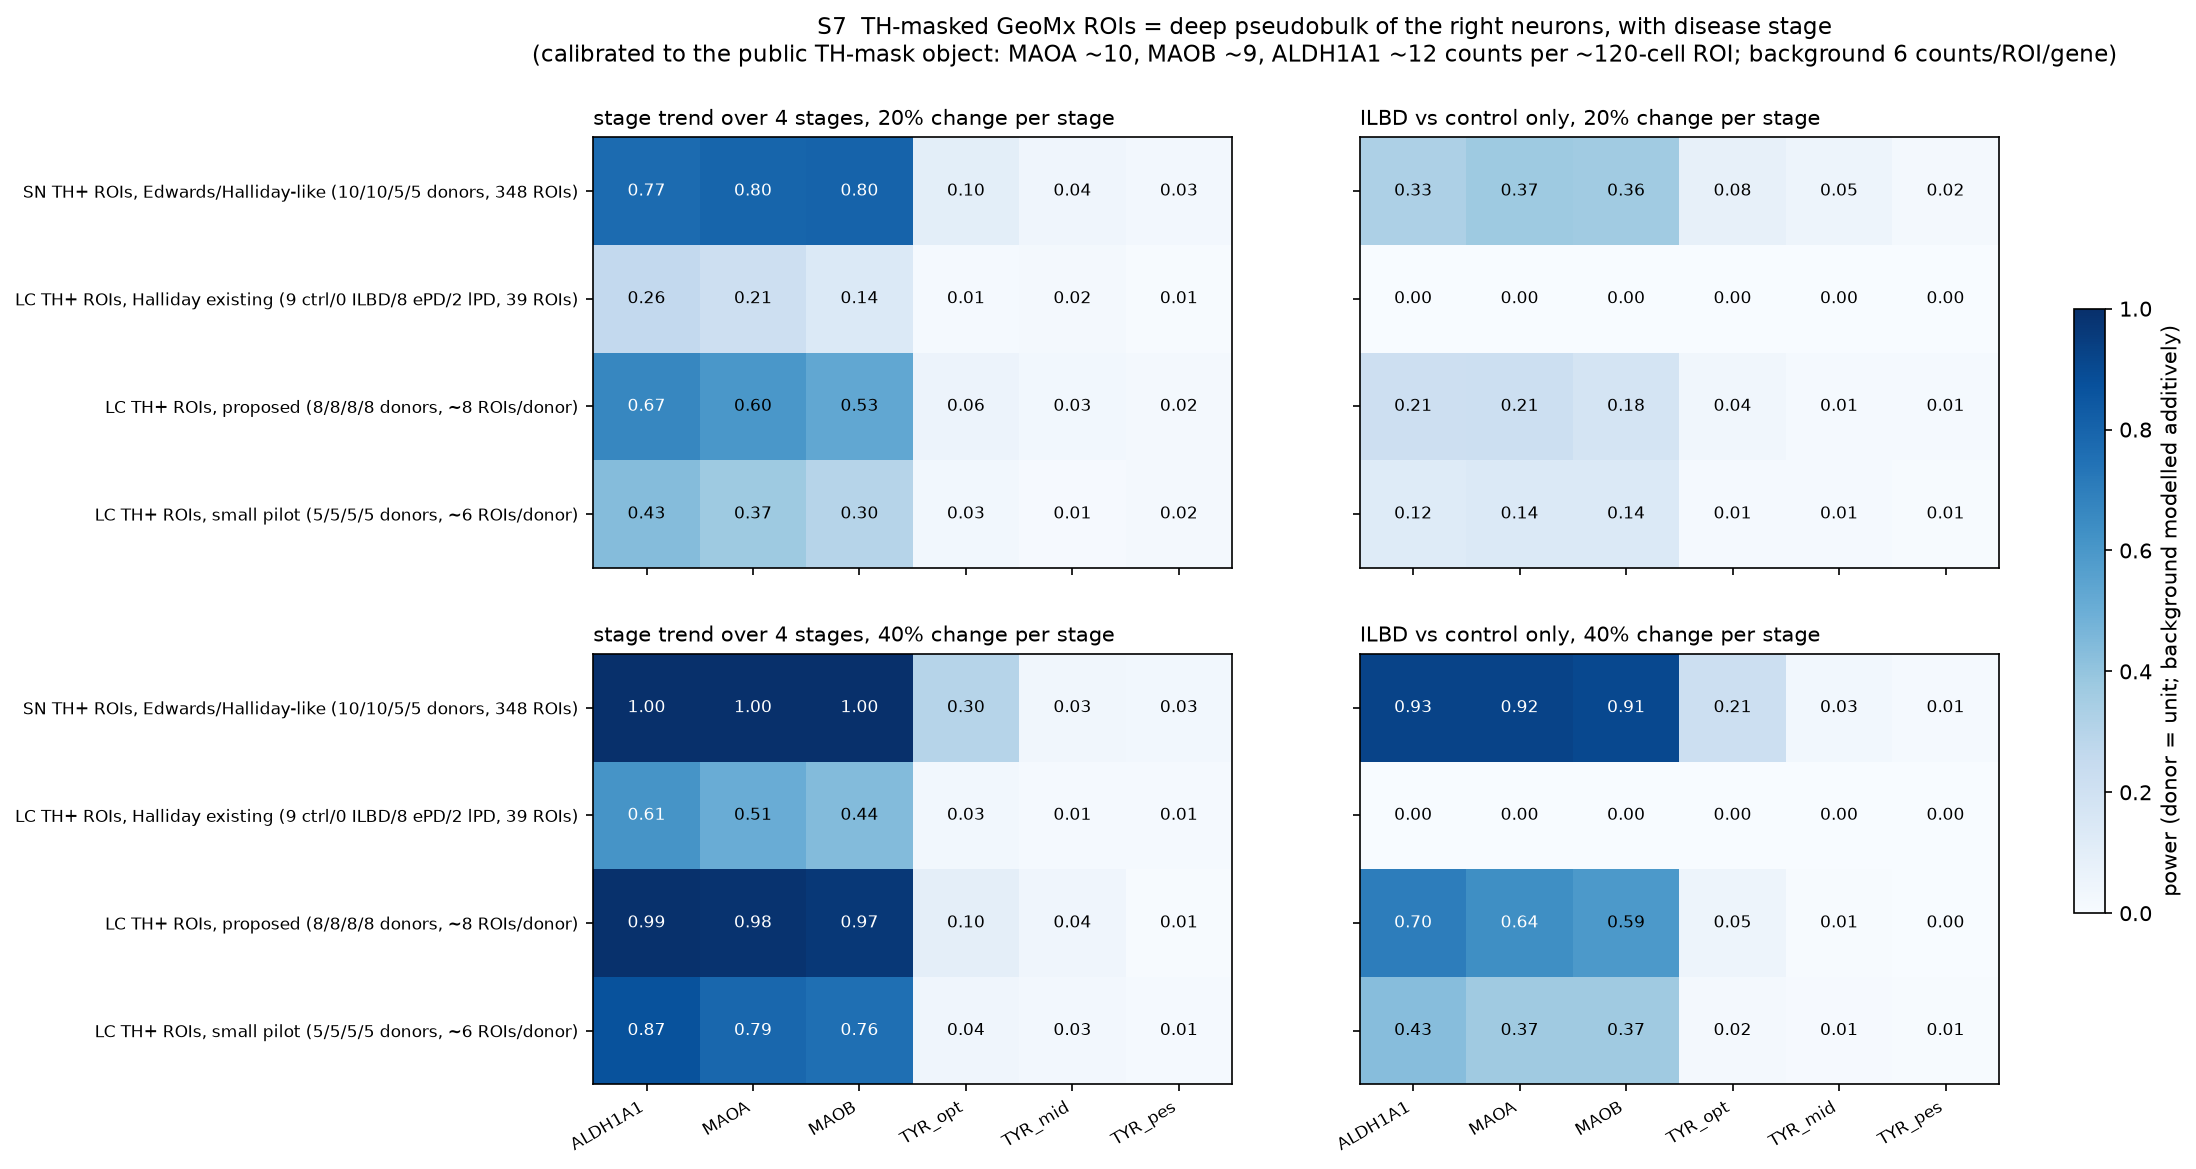

In [8]:
show("S7_geomx_designs.png")

## S8 - Bulk tissue: composition confound and the TYR/TH ratio

In bulk SN, DA-neuron loss alone makes every DA-specific gene "down in PD" (naive test significant in 100% of
cohorts with no per-cell change). Normalising the gene to TH (a per-DA-neuron ratio) removes the composition effect
and retains power for 2-fold per-cell changes down to the plausible TYR level at 40 M reads. Bulk SN with many
donors (GTEx, ~100 non-PD donors) is therefore useful for the baseline question (is TYR transcribed in adult SN,
how does TYR/TH vary with age and sex), not for cell-type attribution.

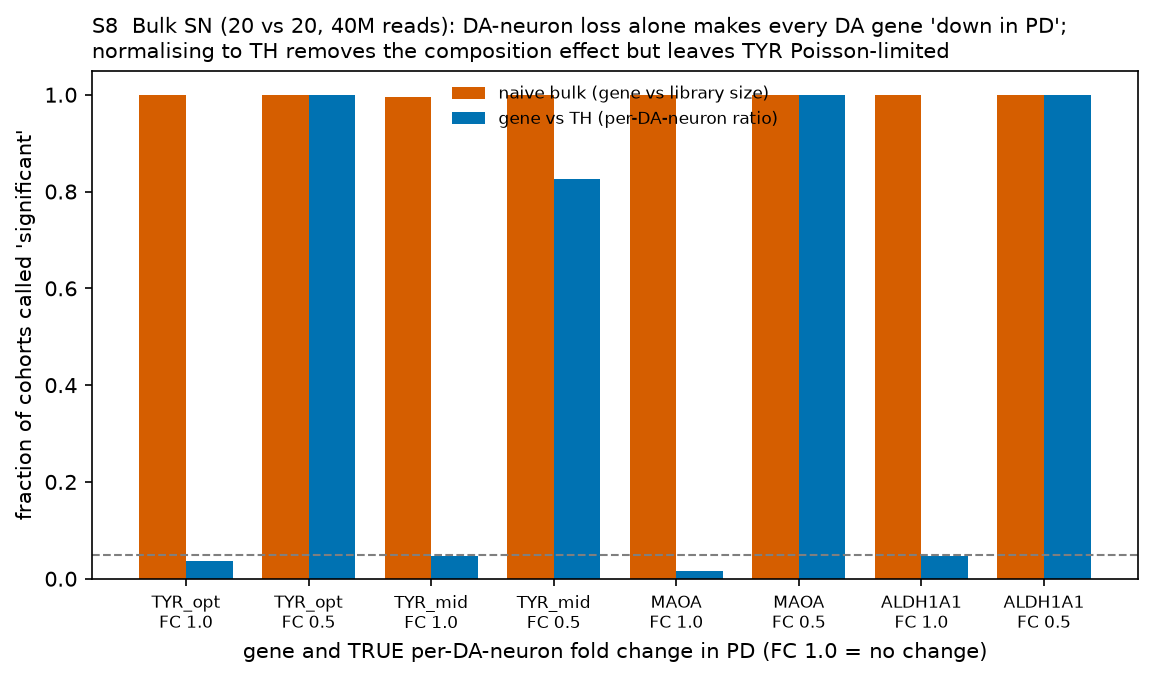

In [9]:
show("S8_bulk_composition_confound.png")

## Key numbers

In [10]:
pd.set_option("display.width", 200)
print("S4 power, FC 0.5 (rows = scenario, cols = gene)")
print(res[(res.section == "S4") & (res.fold_change == 0.5)].pivot(index="scenario", columns="gene", values="power").round(2).to_string())
print("\nS5 subtype power vs pooled nuclei")
print(res[res.section == "S5"].pivot(index="pooled_nuclei", columns="gene", values="power").round(2).to_string())
print("\nS6a false-positive rates (second gene abundance 1e-4, i.e. MAOB-like)")
print(res[(res.section == "S6a") & (res.second_gene_abundance == 1e-4)][["test", "false_positive_rate"]].to_string(index=False))

S4 power, FC 0.5 (rows = scenario, cols = gene)
gene                                                     ALDH1A1  MAOA  MAOB  TYR_mid  TYR_opt  TYR_pes
scenario                                                                                               
LC enriched FANS/LCM (10 / 10, ~400 NE/donor)               1.00  0.99  0.98     0.87     0.98     0.36
LC unsorted pons (10 / 10, ~40 NE/donor)                    0.98  0.98  0.98     0.22     0.67     0.01
SN FANS-enriched, Kamath-like (8 / 10, ~1,200 DA/donor)     1.00  0.98  0.98     0.94     0.98     0.66
SN mega-pool (40 / 50, mixed 5 and 1,200 DA/donor)          1.00  1.00  1.00     1.00     1.00     0.82
SN unsorted, CRN pooled (25 / 40, ~5 DA/donor)              1.00  1.00  1.00     0.09     0.58     0.00
SN unsorted, Lee (8 ctrl / 15 PD, ~5 DA/donor)              0.97  0.94  0.87     0.02     0.20     0.00

S5 subtype power vs pooled nuclei
gene           ALDH1A1  MAOA  MAOB  TYR_mid  TYR_opt  TYR_pes
pooled_nuclei          

## What this means for the analysis plan

1. **Measure first, then re-run this simulation with measured priors.** Notebook 01 already produces the
   per-gene detection fractions and UMIs per DA nucleus; put them into `GENE_P` and re-run.
2. **LC (priority).** No CRN dataset contains pons/LC. What exists: (a) public snRNA-seq - Weber 2024 (~300 NE
   nuclei, deep), Siletti 2023 pons (~113), Basak 2026 (~346): ~765 control NE nuclei after integration, enough
   for the TYR existence test and for MAOA/MAOB/ALDH1A1/COMT/DBH baselines; (b) Mulvey/Martinowich LC Visium
   (33 donors) with neuromelanin intensity modelled against expression - the pigment-vs-catabolism question in
   data that already exist; (c) the Halliday TH-mask LC GeoMx (19 donors, staged) - PD stage in LC, through
   collaboration; (d) new data: TH- and pigment-masked GeoMx on staged LC sections, RNAscope/Xenium for TYR,
   FANS of PHOX2B+ nuclei (~400 NE nuclei/donor gives power ~0.9 for a 2-fold TYR effect at the plausible level).
3. **DA neurons, moderate genes (ALDH1A1, MAOA, MAOB, COMT):** feasible now with CRN data (donor-level pseudobulk,
   quasi-Poisson/edgeR, ambient-corrected, DA neurons re-called with depth-scaled marker thresholds), and with
   disease stage in the Edwards/Chatterton GeoMx TH+ ROIs. Compare within DA subtype (SOX6+ ventral tier vs
   CALB1+ dorsal tier): ALDH1A1 marks the vulnerable ventral-tier neurons, so a PD-vs-control drop in pooled
   DA pseudobulk can be pure survivor composition.
4. **DA neurons, TYR:** at the realistic abundance (~2e-6) a single CRN dataset cannot test PD vs control, but
   the ordered questions are answerable: (a) *is TYR transcribed above the noise floor in DA neurons* - pooled
   CRN SN datasets (Lee + Sulzer + Voet + Jakobsson) give the ~1,000+ control DA nuclei this needs, with the
   cortex nuclei and SN non-neuronal nuclei as the noise floors; (b) *is it higher in the vulnerable subtype* -
   Kamath 2022 (public, ~22k FANS-enriched DA nuclei) has the ~5,000 pooled nuclei this needs; (c) PD vs
   control survivor comparison - only a mega-pool, and of limited meaning because of survivor bias. The most
   sensitive existence test is in situ (RNAscope / Xenium with TYR probes on pigmented neurons): 1-10
   transcripts per cell are visible as dots but invisible to droplet sequencing.
5. **Guard rails:** donor as unit; depth offsets; ambient subtraction; stricter marker thresholds; no imputation;
   pre-registered gene panel; sex as covariate (MAOA/MAOB are X-linked); check that TYR reads are exonic and
   unique to TYR (the TYRL pseudogene) before calling expression.
